# 🌊 Reworked Hydrology Flood Benchmark (Hourly, Storm-Onset Aligned)

This notebook loads the full multi-feature storm hydrology dataset, checks feature redundancy with a correlation matrix, creates a **clean non-redundant dataset** (`data/reworked_hydrology_simple.csv`), documents all `past` vs. `past_future` features and the chronological `train`/`test` split, and visualizes single-river and cross-sectional flood dynamics around $\tau = 0$.

---

### Data Sources
1. **River Telemetry — USGS National Water Information System (NWIS):**
   * Instantaneous Values API (`https://waterservices.usgs.gov/nwis/iv/`): 15-minute gage height (`00065`) and streamflow discharge (`00060`), converted from local station timezones to UTC and averaged to 1-hour steps.
   * Site Metadata API (`https://waterservices.usgs.gov/nwis/site/`): Station latitude, longitude, elevation (`altitude_ft`), and basin drainage area (`drainage_area_sqmi`).
2. **Hourly Weather — Open-Meteo ERA5 Historical Archive:**
   * Archive API (`https://archive-api.open-meteo.com/v1/archive`): Hourly precipitation, barometric surface pressure, 10m wind speed, 2m temperature, relative humidity, and top-layer soil moisture matched to each station's coordinates.

### How Each Sample Was Built (Zero Scaling / Raw Physical Units)
* **Event Onset ($\tau = 0$):** Anchored to the first hour where local storm rainfall reaches $\ge 0.8\text{ mm/hr}$ and triggers sustained storm accumulation ($\ge 6\text{ mm/6h}$ or $\ge 12\text{ mm/12h}$, and $\ge 15\text{ mm}$ storm total)—**not** the flood crest.
* **Window (`[-72h, +72h]`, `145` hours):** `72 hours` of calm pre-storm baseline before $\tau = 0$, followed by `72 hours` of unfolding flood wave after $\tau = 0$.
* **Chronological Split (`N = 500` unique gauges, `0%` overlap):** `train` (`375` gauges from 8 storms in 2017–2022) and `test` (`125` gauges from 5 storms in 2024).


### 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("All libraries imported successfully.")

All libraries imported successfully.


### 2. Load Full Dataset, Summary & Feature Inventory

In [2]:
npz_path = 'data/reworked_domain2_hydrology_storm_onset_hourly.npz'
meta_path = 'data/reworked_domain2_hydrology_metadata.csv'

big_npz = np.load(npz_path)
meta_df = pd.read_csv(meta_path)

arr = big_npz['data']                       # (500, 145, 17)
tau_steps = big_npz['tau_steps']            # [-72, ..., 0, ..., +72]
feat_names = [str(f) for f in big_npz['feature_names']]
past_feats = [str(f) for f in big_npz['past_feature_names']]
pf_feats   = [str(f) for f in big_npz['past_future_feature_names']]
static_feats = [str(f) for f in big_npz['static_feature_names']]

print("=== FULL DATASET SUMMARY ===")
print(f"3D Tensor Shape : {arr.shape}  (N={arr.shape[0]} rivers, T={arr.shape[1]} hours, C={arr.shape[2]} dynamic features)")
print(f"Static Shape    : {big_npz['static_features'].shape}  ({len(static_feats)} station features)")
print(f"Unique Gauges   : {meta_df['site_id'].nunique()} / {len(meta_df)} across {meta_df['state'].nunique()} US states")
print(f"Missing Values  : {int(np.isnan(arr).sum())} NaNs")
print(f"\nPast-Only Features ({len(past_feats)})   : {past_feats}")
print(f"Past-Future Features ({len(pf_feats)}): {pf_feats}")
print(f"Static Features ({len(static_feats)})     : {static_feats}")

# Flatten into a full long-format DataFrame for easy inspection
N, T, _ = arr.shape
onset_dt = pd.to_datetime(meta_df['onset_utc'])
ts_list = [dt + pd.to_timedelta(tau_steps, unit='h') for dt in onset_dt]
ts_flat = pd.DatetimeIndex(np.concatenate([t.values for t in ts_list]))

full_df = pd.DataFrame({
    'sample_id': np.repeat(meta_df['sample_id'].values, T),
    'split': np.repeat(meta_df['split'].values, T),
    'storm': np.repeat(meta_df['storm_name'].values, T),
    'state': np.repeat(meta_df['state'].values, T),
    'timestamp_utc': ts_flat.strftime('%Y-%m-%d %H:%M:%S'),
    'tau_hour': np.tile(tau_steps, N),
    'hour_of_day': ts_flat.hour,
})
for c_i, name in enumerate(feat_names):
    full_df[name] = arr[:, :, c_i].ravel()
for s_i, name in enumerate(static_feats):
    full_df[name] = np.repeat(big_npz['static_features'][:, s_i], T)

print(f"\nFlattened Full DataFrame Shape: {full_df.shape}")
print("Metadata Columns:", list(meta_df.columns))
display(meta_df[['sample_id', 'state', 'storm_name', 'split', 'onset_utc', 'peak_tau_hours', 'baseline_stage_ft', 'peak_stage_ft', 'surge_ft']].head(6))
display(full_df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

=== FULL DATASET SUMMARY ===
3D Tensor Shape : (500, 145, 17)  (N=500 rivers, T=145 hours, C=17 dynamic features)
Static Shape    : (500, 4)  (4 station features)
Unique Gauges   : 500 / 500 across 17 US states
Missing Values  : 0 NaNs

Past-Only Features (6)   : ['gage_height_ft', 'discharge_cfs', 'stage_velocity_ft_hr', 'stage_acceleration_ft_hr2', 'discharge_velocity_cfs_hr', 'stage_rolling_std_6h_ft']
Past-Future Features (11): ['precip_mm_hr', 'precip_rolling_6h_mm', 'precip_rolling_24h_mm', 'surface_pressure_hpa', 'wind_speed_10m_ms', 'temperature_2m_c', 'relative_humidity_pct', 'soil_moisture_m3m3', 'hour_sin', 'hour_cos', 'day_of_week']
Static Features (4)     : ['latitude', 'longitude', 'altitude_ft', 'drainage_area_sqmi']

Flattened Full DataFrame Shape: (72500, 28)
Metadata Columns: ['sample_id', 'site_id', 'station_name', 'state', 'storm_name', 'split', 'onset_utc', 'window_start_utc', 'window_end_utc', 'peak_utc', 'peak_tau_hours', 'baseline_stage_ft', 'onset_stage_ft', 'p

,sample_id,state,storm_name,split,onset_utc,peak_tau_hours,baseline_stage_ft,peak_stage_ft,surge_ft
0,USGS_08053500__Harvey_2017,TX,Harvey_2017,train,2017-08-24 07:00:00,13,2.270,4.425,2.155
1,USGS_08044500__Harvey_2017,TX,Harvey_2017,train,2017-08-24 08:00:00,44,5.620,9.315,3.695
2,USGS_08044800__Harvey_2017,TX,Harvey_2017,train,2017-08-24 08:00:00,32,3.021,9.213,6.191
3,USGS_08052780__Harvey_2017,TX,Harvey_2017,train,2017-08-24 09:00:00,11,2.660,11.003,8.343
4,USGS_08050800__Harvey_2017,TX,Harvey_2017,train,2017-08-24 10:00:00,13,3.816,13.018,9.201
5,USGS_08171300__Harvey_2017,TX,Harvey_2017,train,2017-08-25 11:00:00,48,3.164,7.416,4.252


,count,mean,std,min,50%,max
tau_hour,72500.0,0.00,41.86,-72.00,0.00,72.00
hour_of_day,72500.0,11.51,6.91,0.00,12.00,23.00
gage_height_ft,72500.0,6.17,7.45,0.08,3.73,79.49
discharge_cfs,72500.0,1571.90,6076.89,0.00,97.00,147000.00
stage_velocity_ft_hr,72500.0,0.02,0.32,-6.81,0.00,9.87
stage_acceleration_ft_hr2,72500.0,-0.00,0.23,-7.55,0.00,8.39
discharge_velocity_cfs_hr,72500.0,18.36,478.60,-11150.00,0.00,52175.00
stage_rolling_std_6h_ft,72500.0,0.19,0.47,0.00,0.03,9.82
precip_mm_hr,72500.0,0.83,2.51,0.00,0.00,89.60
precip_rolling_6h_mm,72500.0,5.01,12.37,0.00,0.10,335.40


### 3. Derived Features Check & Correlation Matrix (Justifying Redundancy Removal)

Below we test an additional causal derived feature (`stage_change_6h` = 6-hour stage rise/fall) alongside the full set of candidate features, and compute the **median within-river Pearson correlation matrix** across all 500 stations:
* **Redundant (`|r| > 0.90`) -> Remove:**
  * `discharge_cfs` vs. `gage_height_ft` (`r = +0.98`): USGS derives discharge from stage via rating curves.
  * `discharge_velocity_cfs_hr` vs. `stage_velocity_ft_hr` (`r = +0.95`): Duplicate rate of change.
* **Noisy / overlapping derivatives -> Remove:**
  * `stage_acceleration_ft_hr2`: Noisy 2nd finite difference (`r = -0.18` with stage).
  * `stage_rolling_std_6h_ft`: Scales with flood wave steepness (`r = +0.69` with stage).
  * `precip_rolling_6h_mm` (`r = +0.74` with `precip_mm_hr`): We keep `precip_rolling_24h_mm` (`rain_24h_sum`) instead because it has much lower correlation with raw hourly rain (`r = +0.36`) while tracking cumulative basin water (`r = +0.72` with river stage).
  * `hour_sin` & `hour_cos`: Replaced with a single plain `hour_of_day` (`0..23`) integer column.
* **Non-redundant derived features -> Keep:**
  * `stage_change_1h` (`stage_velocity_ft_hr`) has **almost zero correlation** with `gage_height_ft` (`r = +0.08`), capturing whether the river is currently rising, cresting, or receding.
  * `stage_change_6h` has **low correlation** with `gage_height_ft` (`r = +0.31`) while capturing 6-hour trend.


=== KEY CORRELATION PAIRS (MEDIAN WITHIN-RIVER PEARSON r) ===
  gage_height_ft             vs discharge_cfs              -> r = +0.982  | DROP discharge_cfs (near-duplicate of stage)
  stage_velocity_ft_hr       vs discharge_velocity_cfs_hr  -> r = +0.956  | DROP discharge_velocity_cfs_hr (near-duplicate)
  precip_mm_hr               vs precip_rolling_6h_mm       -> r = +0.742  | DROP precip_rolling_6h_mm (high overlap with hourly rain)
  precip_mm_hr               vs precip_rolling_24h_mm      -> r = +0.363  | KEEP rain_24h_sum (low corr with 1h rain, r=+0.72 with stage)
  gage_height_ft             vs stage_velocity_ft_hr       -> r = +0.081  | KEEP stage_change_1h (uncorrelated with stage level)
  gage_height_ft             vs stage_change_6h            -> r = +0.314  | Low corr with stage level
  gage_height_ft             vs precip_rolling_24h_mm      -> r = +0.723  | Strong physical link between cumulative rain & stage


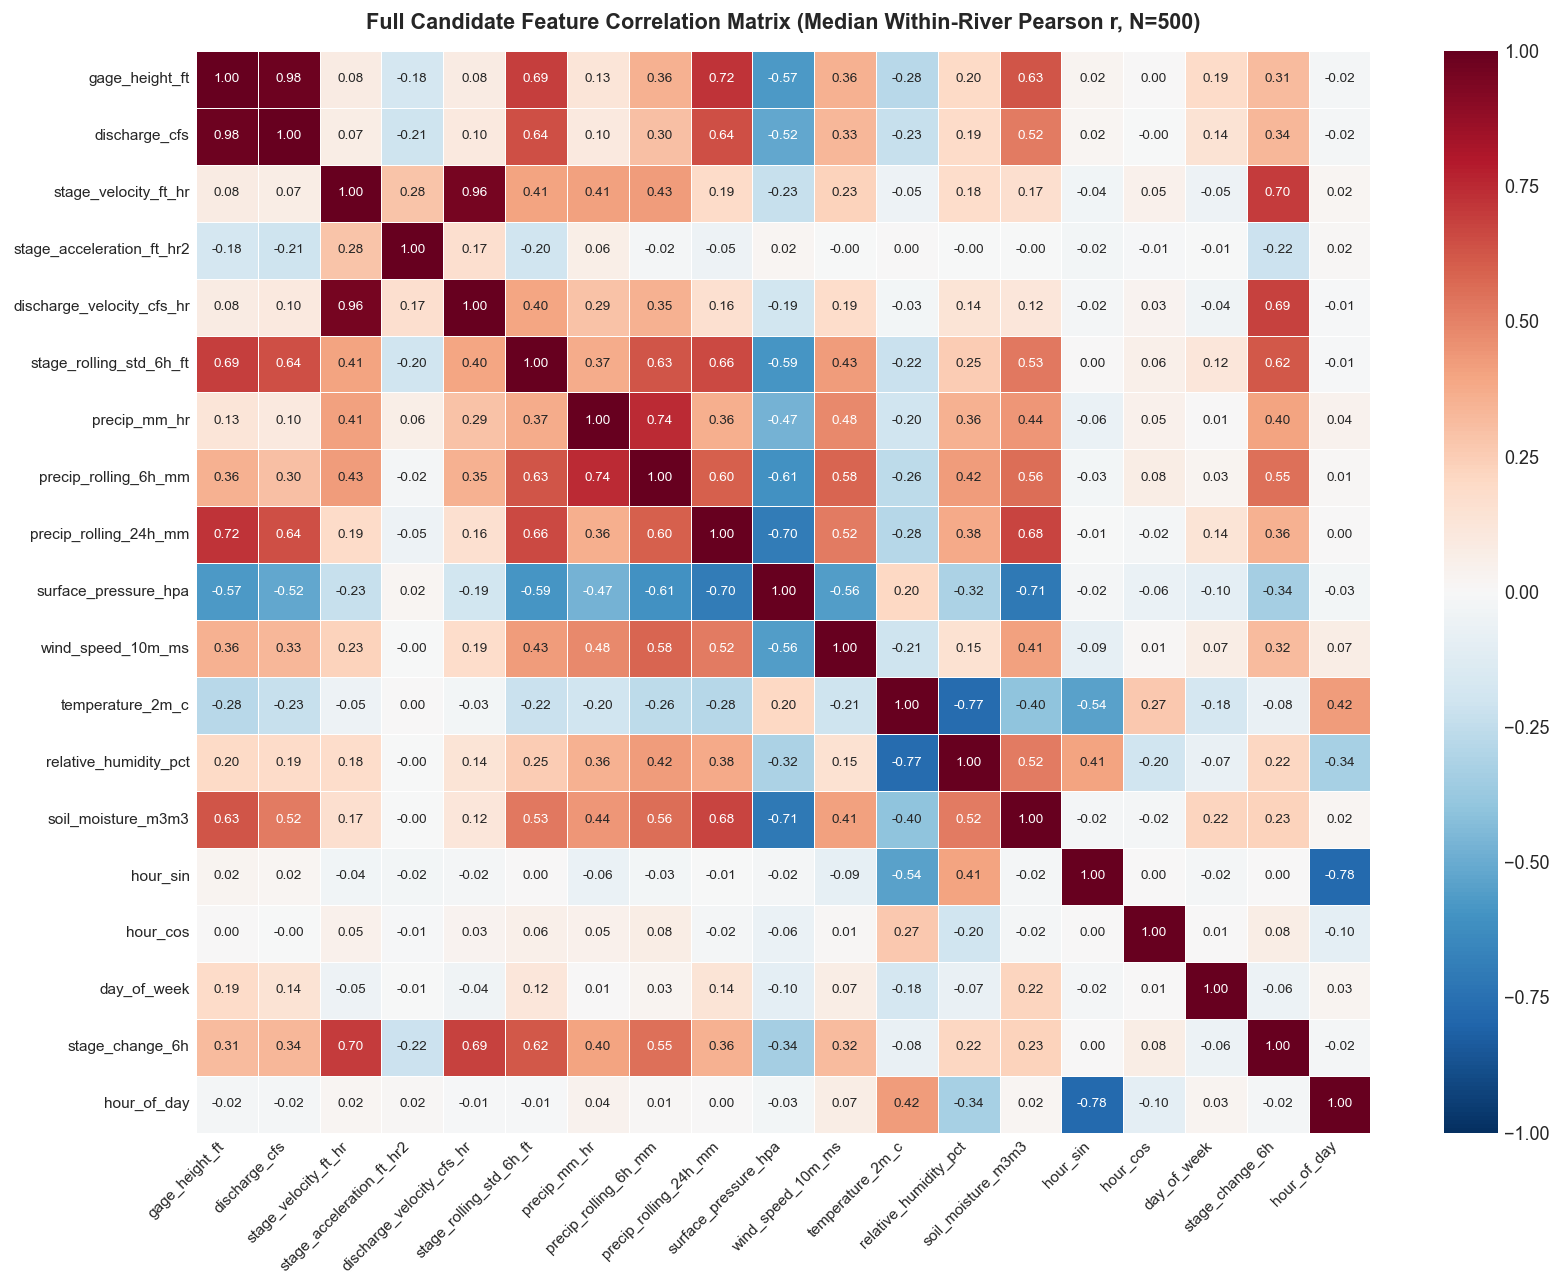

In [3]:
# Add candidate 6-hour backward stage change inside the window (causal lag; padded with 0 at window edge for corr check)
full_df['stage_change_6h'] = (
    full_df.groupby('sample_id')['gage_height_ft']
    .diff(6)
    .fillna(0.0)
    .astype(np.float32)
)

candidate_cols = feat_names + ['stage_change_6h', 'hour_of_day']

# Compute within-river correlation matrix (skipping first 6 edge hours for clean stage_change_6h) and take median across 500 rivers
sub_blocks = full_df[full_df['tau_hour'] >= -66].copy()
corr_list = []
for _, grp in sub_blocks.groupby('sample_id', sort=False):
    mat = grp[candidate_cols].values
    if (mat.std(axis=0) > 1e-8).all():
        corr_list.append(np.corrcoef(mat, rowvar=False))

med_corr_full = pd.DataFrame(np.nanmedian(corr_list, axis=0), index=candidate_cols, columns=candidate_cols)

print("=== KEY CORRELATION PAIRS (MEDIAN WITHIN-RIVER PEARSON r) ===")
check_pairs = [
    ('gage_height_ft', 'discharge_cfs', 'DROP discharge_cfs (near-duplicate of stage)'),
    ('stage_velocity_ft_hr', 'discharge_velocity_cfs_hr', 'DROP discharge_velocity_cfs_hr (near-duplicate)'),
    ('precip_mm_hr', 'precip_rolling_6h_mm', 'DROP precip_rolling_6h_mm (high overlap with hourly rain)'),
    ('precip_mm_hr', 'precip_rolling_24h_mm', 'KEEP rain_24h_sum (low corr with 1h rain, r=+0.72 with stage)'),
    ('gage_height_ft', 'stage_velocity_ft_hr', 'KEEP stage_change_1h (uncorrelated with stage level)'),
    ('gage_height_ft', 'stage_change_6h', 'Low corr with stage level'),
    ('gage_height_ft', 'precip_rolling_24h_mm', 'Strong physical link between cumulative rain & stage'),
]
for a, b, note in check_pairs:
    print(f"  {a:26s} vs {b:26s} -> r = {med_corr_full.loc[a, b]:+.3f}  | {note}")

fig, ax = plt.subplots(figsize=(13, 10), dpi=130)
sns.heatmap(med_corr_full, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            annot_kws={'size': 7.5}, linewidths=0.4, ax=ax)
ax.set_title("Full Candidate Feature Correlation Matrix (Median Within-River Pearson r, N=500)", fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=8.5)
plt.yticks(fontsize=8.5)
plt.tight_layout()
plt.show()

### 4. Create the Clean Non-Redundant Dataset (`data/reworked_hydrology_simple.csv`)

Dropping the redundant/noisy derived columns (`discharge_cfs`, `discharge_velocity_cfs_hr`, `stage_acceleration_ft_hr2`, `stage_rolling_std_6h_ft`, `precip_rolling_6h_mm`, `hour_sin`, `hour_cos`) leaves **11 dynamic features + 2 static features**, with **zero redundant pairs (`max |r| <= 0.77`)**. We verify the post-pruning correlation matrix and save `data/reworked_hydrology_simple.csv`.


In [4]:
simple_df = pd.DataFrame({
    'sample_id': full_df['sample_id'],
    'split': full_df['split'],
    'storm': full_df['storm'],
    'state': full_df['state'],
    'timestamp_utc': full_df['timestamp_utc'],
    'tau_hour': full_df['tau_hour'],
    'stage_ft': full_df['gage_height_ft'].round(3),
    'stage_change_1h': full_df['stage_velocity_ft_hr'].round(3),
    'rain_mm_hr': full_df['precip_mm_hr'].round(2),
    'rain_24h_sum': full_df['precip_rolling_24h_mm'].round(2),
    'pressure_hpa': full_df['surface_pressure_hpa'].round(2),
    'wind_ms': full_df['wind_speed_10m_ms'].round(2),
    'temp_c': full_df['temperature_2m_c'].round(2),
    'humidity_pct': full_df['relative_humidity_pct'].round(1),
    'soil_moisture': full_df['soil_moisture_m3m3'].round(4),
    'hour_of_day': full_df['hour_of_day'],
    'day_of_week': full_df['day_of_week'].astype(int),
    'drainage_area_sqmi': full_df['drainage_area_sqmi'].round(2),
    'altitude_ft': full_df['altitude_ft'].round(1),
})

simple_csv = 'data/reworked_hydrology_simple.csv'
simple_df.to_csv(simple_csv, index=False)

# Verify zero high-redundancy pairs remain
dyn_cols = [
    'stage_ft', 'stage_change_1h', 'rain_mm_hr', 'rain_24h_sum',
    'pressure_hpa', 'wind_ms', 'temp_c', 'humidity_pct',
    'soil_moisture', 'hour_of_day', 'day_of_week'
]
clean_corrs = []
for _, grp in simple_df.groupby('sample_id', sort=False):
    m = grp[dyn_cols].values
    if (m.std(axis=0) > 1e-8).all():
        clean_corrs.append(np.corrcoef(m, rowvar=False))
med_clean = np.nanmedian(clean_corrs, axis=0)
max_off_diag = float(np.abs(med_clean[~np.eye(len(dyn_cols), dtype=bool)]).max())

print(f"Saved: {simple_csv} ({os.path.getsize(simple_csv)/1024/1024:.2f} MB)")
print(f"Shape: {simple_df.shape} | Nulls: {int(simple_df.isna().sum().sum())} | Max off-diagonal |r|: {max_off_diag:.3f}")
display(simple_df.head(5))

Saved: data/reworked_hydrology_simple.csv (9.23 MB)
Shape: (72500, 19) | Nulls: 0 | Max off-diagonal |r|: 0.766


,sample_id,split,storm,state,timestamp_utc,tau_hour,stage_ft,stage_change_1h,rain_mm_hr,rain_24h_sum,pressure_hpa,wind_ms,temp_c,humidity_pct,soil_moisture,hour_of_day,day_of_week,drainage_area_sqmi,altitude_ft
0,USGS_08053500__Harvey_2017,train,Harvey_2017,TX,2017-08-21 07:00:00,-72,2.330,0.000,0.0,0.6,991.799988,5.14,27.500000,67.0,0.309,7,0,400.0,606.599976
1,USGS_08053500__Harvey_2017,train,Harvey_2017,TX,2017-08-21 08:00:00,-71,2.330,0.000,0.0,0.6,991.700012,4.85,27.500000,60.0,0.309,8,0,400.0,606.599976
2,USGS_08053500__Harvey_2017,train,Harvey_2017,TX,2017-08-21 09:00:00,-70,2.330,0.000,0.0,0.6,991.799988,4.28,26.799999,64.0,0.309,9,0,400.0,606.599976
3,USGS_08053500__Harvey_2017,train,Harvey_2017,TX,2017-08-21 10:00:00,-69,2.330,0.000,0.0,0.6,991.799988,3.82,26.400000,69.0,0.309,10,0,400.0,606.599976
4,USGS_08053500__Harvey_2017,train,Harvey_2017,TX,2017-08-21 11:00:00,-68,2.332,0.002,0.0,0.6,992.299988,3.11,25.900000,75.0,0.309,11,0,400.0,606.599976


### 5. Feature Inventory: Past-Only vs. Past-Future vs. Static

In [5]:
ID_COLS = ['sample_id', 'split', 'storm', 'state', 'timestamp_utc', 'tau_hour']
TARGET = 'stage_ft'
PAST_ONLY = ['stage_ft', 'stage_change_1h']   # Observed ONLY up to tau_hour <= 0; masked for tau_hour > 0
PAST_FUTURE = [                               # Known across ALL tau_hour (-72 to +72) via weather forecasts & calendar
    'rain_mm_hr', 'rain_24h_sum', 'pressure_hpa', 'wind_ms',
    'temp_c', 'humidity_pct', 'soil_moisture', 'hour_of_day', 'day_of_week'
]
STATIC = ['drainage_area_sqmi', 'altitude_ft'] # Constant physical station metadata

role_rows = []
for c in simple_df.columns:
    if c in ID_COLS:
        role, avail = 'ID / Time / Split', 'Metadata'
    elif c == TARGET:
        role, avail = 'Target (Past-Only input)', 'Observed <= 0; Predict > 0'
    elif c in PAST_ONLY:
        role, avail = 'Past-Only Covariate', 'Observed <= 0; Masked > 0'
    elif c in PAST_FUTURE:
        role, avail = 'Past-Future Covariate', 'Known for all tau (-72..+72)'
    else:
        role, avail = 'Static Station Feature', 'Constant per river'
    role_rows.append({'Column': c, 'Role': role, 'Deployment Availability': avail, 'Dtype': str(simple_df[c].dtype)})

role_df = pd.DataFrame(role_rows)
print(f"Total Columns: {len(simple_df.columns)} | Dynamic Features: {len(PAST_ONLY) + len(PAST_FUTURE)} ({len(PAST_ONLY)} Past + {len(PAST_FUTURE)} Past-Future) | Static: {len(STATIC)}")
display(role_df)

Total Columns: 19 | Dynamic Features: 11 (2 Past + 9 Past-Future) | Static: 2


,Column,Role,Deployment Availability,Dtype
0,sample_id,ID / Time / Split,Metadata,object
1,split,ID / Time / Split,Metadata,object
2,storm,ID / Time / Split,Metadata,object
3,state,ID / Time / Split,Metadata,object
4,timestamp_utc,ID / Time / Split,Metadata,object
5,tau_hour,ID / Time / Split,Metadata,int32
6,stage_ft,Target (Past-Only input),Observed <= 0; Predict > 0,float32
7,stage_change_1h,Past-Only Covariate,Observed <= 0; Masked > 0,float32
8,rain_mm_hr,Past-Future Covariate,Known for all tau (-72..+72),float32
9,rain_24h_sum,Past-Future Covariate,Known for all tau (-72..+72),float32


### 6. Chronological Train / Test Split Summary

In [6]:
split_summary = simple_df.groupby('split').agg(
    rivers=('sample_id', 'nunique'),
    rows=('sample_id', 'count'),
    storms=('storm', 'nunique'),
    states=('state', 'nunique'),
    earliest_utc=('timestamp_utc', 'min'),
    latest_utc=('timestamp_utc', 'max'),
)
storm_split = simple_df.groupby(['split', 'storm']).agg(
    rivers=('sample_id', 'nunique'),
    states=('state', lambda s: ','.join(sorted(s.unique()))),
    start_utc=('timestamp_utc', 'min'),
    end_utc=('timestamp_utc', 'max'),
).sort_values('start_utc')

overlap = set(simple_df[simple_df['split']=='train']['sample_id']).intersection(
    set(simple_df[simple_df['split']=='test']['sample_id'])
)
print(f"Train/Test station overlap: {len(overlap)} (0% overlap, strictly chronological 2017-2022 -> 2024)")
display(split_summary)
display(storm_split)

Train/Test station overlap: 0 (0% overlap, strictly chronological 2017-2022 -> 2024)


,rivers,rows,storms,states,earliest_utc,latest_utc
split,,,,,,
test,125,18125,5,14,2024-06-15 07:00:00,2024-10-12 13:00:00
train,375,54375,8,14,2017-08-21 07:00:00,2022-10-03 14:00:00


rivers             states            start_utc  \
split storm                                                                
train Harvey_2017             55              LA,TX  2017-08-21 07:00:00   
      Irma_2017               55           FL,GA,SC  2017-09-05 17:00:00   
      Florence_2018           55           NC,SC,VA  2018-09-07 19:00:00   
      Michael_2018            55        FL,GA,NC,VA  2018-10-06 20:00:00   
      Midwest_2019            34           IA,NE,SD  2019-03-09 15:00:00   
      Imelda_2019             11              LA,TX  2019-09-13 18:00:00   
      Ida_2021                55        MD,NJ,NY,PA  2021-08-26 17:00:00   
      Ian_2022                55           FL,NC,SC  2022-09-23 19:00:00   
test  Midwest_Flood_2024       5           IA,MN,NE  2024-06-15 07:00:00   
      Beryl_2024              35           AR,LA,TX  2024-07-03 13:00:00   
      Debby_2024              35     FL,NC,NY,PA,SC  2024-07-30 18:00:00   
      Helene_2024             35  FL,GA,NC,SC,TN,VA  2024-09-21 08:00:00   
      Milton_2024             15                 FL  2024-10-05 20:00:00   

                                      end_utc  
split storm                                    
train Harvey_2017         2017-08-31 14:00:00  
      Irma_2017           2017-09-14 18:00:00  
      Florence_2018       2018-09-20 11:00:00  
      Michael_2018        2018-10-14 19:00:00  
      Midwest_2019        2019-03-16 13:00:00  
      Imelda_2019         2019-09-24 02:00:00  
      Ida_2021            2021-09-04 20:00:00  
      Ian_2022            2022-10-03 14:00:00  
test  Midwest_Flood_2024  2024-06-29 05:00:00  
      Beryl_2024          2024-07-11 22:00:00  
      Debby_2024          2024-08-12 08:00:00  
      Helene_2024         2024-09-30 04:00:00  
      Milton_2024         2024-10-12 13:00:00

### 7. Before & After Surge Visualization (1 Sample River + All 500 Train vs. Test Rivers)

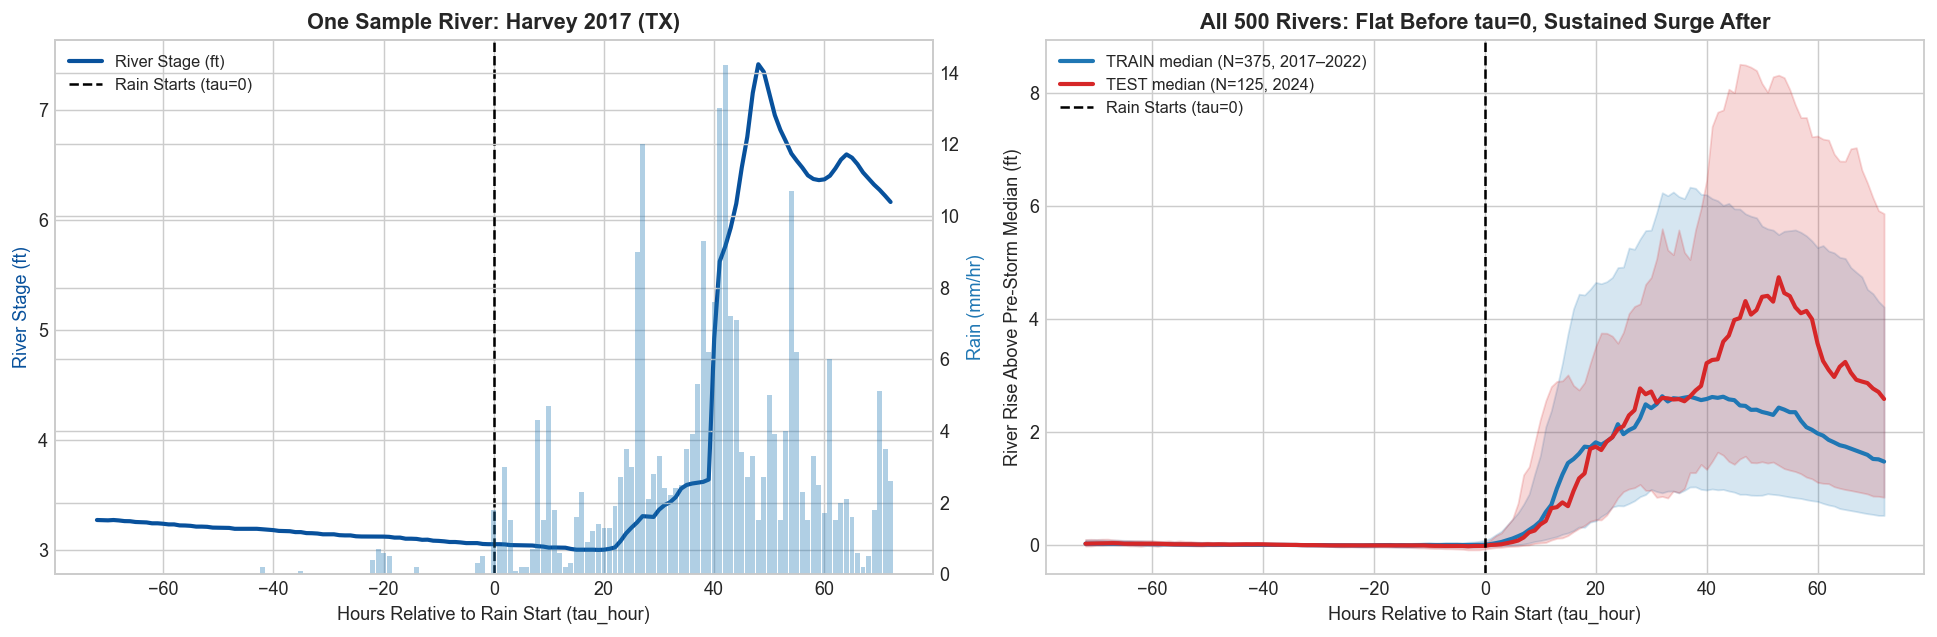

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=130)

# Left Panel: One Sample River (Harvey 2017, TX)
s1 = simple_df[simple_df['sample_id'] == 'USGS_08171300__Harvey_2017']
ax1 = axes[0]
l1, = ax1.plot(s1['tau_hour'], s1['stage_ft'], color='#08519c', lw=2.3, label='River Stage (ft)')
l2 = ax1.axvline(0, color='black', ls='--', lw=1.4, label='Rain Starts (tau=0)')
ax1.set_title("One Sample River: Harvey 2017 (TX)", fontweight='bold')
ax1.set_xlabel("Hours Relative to Rain Start (tau_hour)")
ax1.set_ylabel("River Stage (ft)", color='#08519c')
ax1_r = ax1.twinx()
ax1_r.bar(s1['tau_hour'], s1['rain_mm_hr'], color='#1f77b4', alpha=0.35, width=0.9, label='Rain (mm/hr)')
ax1_r.set_ylabel("Rain (mm/hr)", color='#1f77b4')
ax1.legend(handles=[l1, l2], loc='upper left', fontsize=9)

# Right Panel: Median & IQR across all Train (375) vs Test (125) Rivers
base = simple_df[simple_df['tau_hour'] < 0].groupby('sample_id')['stage_ft'].median().rename('base')
df_plot = simple_df.join(base, on='sample_id')
df_plot['rise_ft'] = df_plot['stage_ft'] - df_plot['base']

ax2 = axes[1]
for split_name, col, lbl in [('train', '#1f77b4', 'TRAIN median (N=375, 2017–2022)'),
                             ('test', '#d62728', 'TEST median (N=125, 2024)')]:
    sub = df_plot[df_plot['split'] == split_name].groupby('tau_hour')['rise_ft']
    ax2.plot(sub.median().index, sub.median().values, color=col, lw=2.3, label=lbl)
    ax2.fill_between(sub.median().index, sub.quantile(0.25), sub.quantile(0.75), color=col, alpha=0.18)
ax2.axvline(0, color='black', ls='--', lw=1.4, label='Rain Starts (tau=0)')
ax2.set_title("All 500 Rivers: Flat Before tau=0, Sustained Surge After", fontweight='bold')
ax2.set_xlabel("Hours Relative to Rain Start (tau_hour)")
ax2.set_ylabel("River Rise Above Pre-Storm Median (ft)")
ax2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('data/reworked_hydrology_simple_overview.png', dpi=150)
plt.show()